CSV file created successfully!
   area_sqft  bedrooms  age_years  distance_km  price_inr
0        800         2         10            8    4200000
1        950         2          8            6    5100000
2       1100         2          5            5    6300000
3       1250         3          7            7    6900000
4       1400         3          4            4    8500000
(20, 5)
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   area_sqft    20 non-null     int64
 1   bedrooms     20 non-null     int64
 2   age_years    20 non-null     int64
 3   distance_km  20 non-null     int64
 4   price_inr    20 non-null     int64
dtypes: int64(5)
memory usage: 932.0 bytes
area_sqft      0
bedrooms       0
age_years      0
distance_km    0
price_inr      0
dtype: int64
         area_sqft   bedrooms  age_years  distance_km     price_inr
count    20.000000  20.000000  20

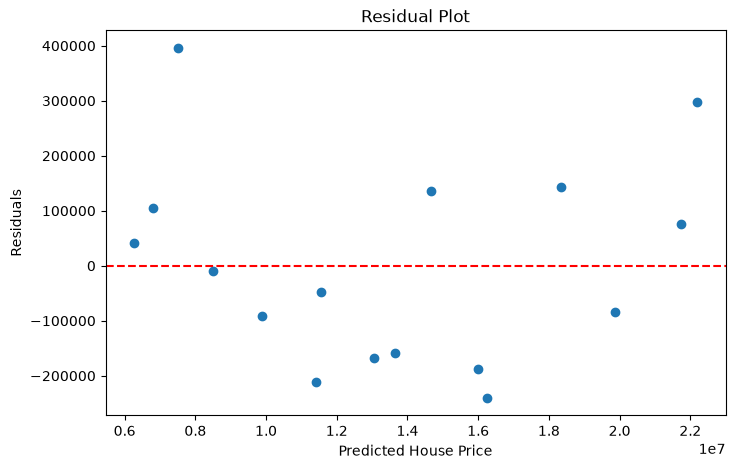

    Actual_Price  Predicted_Price       Residual  Absolute_Residual
5        7900000     7.504074e+06  395925.560884      395925.560884
18      22500000     2.220166e+07  298338.154700      298338.154700
13      16000000     1.624042e+07 -240423.917947      240423.917947


In [4]:
# 4. Practical Task — Improve the House-Price Model
# Continue from yesterday's house-price assignment. Reuse your dataset if it has the columns below. Otherwise, create house_prices.csv using this fictional learning dataset (not real market prices).
# area_sqft	bedrooms	age_years	distance_km	price_inr
# 800	2	10	8	4200000
# 950	2	8	6	5100000
# 1100	2	5	5	6300000
# 1250	3	7	7	6900000
# 1400	3	4	4	8500000
# 1550	3	12	9	7900000
# 1700	3	6	5	9800000
# 1850	3	3	3	11500000
# 2000	4	8	6	11200000
# 2150	4	5	4	12900000
# 2300	4	2	3	14800000
# 2450	4	10	8	13500000
# 2600	4	4	5	15800000
# 2750	4	7	6	16000000
# 2900	5	3	2	18500000
# 3050	5	9	7	17400000
# 3200	5	4	4	19800000
# 3350	5	6	5	20500000
# 3500	5	2	3	22500000
# 3650	5	8	6	21800000
# Step 1 — Load and inspect
# Load the CSV with pandas. Check head(), shape, info(), missing values and describe(). Set price_inr as the target; the other four columns are candidate features.
import pandas as pd
import pandas as pd

data = {
    "area_sqft": [800, 950, 1100, 1250, 1400, 1550, 1700, 1850, 2000, 2150,
                  2300, 2450, 2600, 2750, 2900, 3050, 3200, 3350, 3500, 3650],

    "bedrooms": [2, 2, 2, 3, 3, 3, 3, 3, 4, 4,
                 4, 4, 4, 4, 5, 5, 5, 5, 5, 5],

    "age_years": [10, 8, 5, 7, 4, 12, 6, 3, 8, 5,
                  2, 10, 4, 7, 3, 9, 4, 6, 2, 8],

    "distance_km": [8, 6, 5, 7, 4, 9, 5, 3, 6, 4,
                    3, 8, 5, 6, 2, 7, 4, 5, 3, 6],

    "price_inr": [4200000, 5100000, 6300000, 6900000, 8500000,
                  7900000, 9800000, 11500000, 11200000, 12900000,
                  14800000, 13500000, 15800000, 16000000, 18500000,
                  17400000, 19800000, 20500000, 22500000, 21800000]
}

df = pd.DataFrame(data)

df.to_csv("house_prices.csv", index=False)

print("CSV file created successfully!")
df = pd.read_csv("house_prices.csv")

print(df.head())
print(df.shape)
df.info()
print(df.isnull().sum())
print(df.describe())

# Step 2 — Create one train/test split
# Use train_test_split(test_size=0.2, random_state=42). Split before fitting. Reuse this exact split for all models to make the comparison fair.
from sklearn.model_selection import train_test_split

X = df[["area_sqft", "bedrooms", "age_years", "distance_km"]]

y = df["price_inr"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)
# Step 3 — Train three models
# •	Model A — Baseline: area_sqft only.
# •	Model B — Multiple regression: area_sqft, bedrooms, age_years and distance_km.
# •	Model C — Your selected feature combination. Choose fewer or different features and justify your decision.
# For each model, train LinearRegression with fit(), predict the test data, then calculate MAE, MSE, RMSE and R².
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
def evaluate_model(features, model_name):

    # Select training and testing features from the same split
    X_train_selected = X_train[features]
    X_test_selected = X_test[features]

    # Create model
    model = LinearRegression()

    # Train model
    model.fit(X_train_selected, y_train)

    # Make predictions
    y_pred = model.predict(X_test_selected)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    print("\n", model_name)
    print("Features:", features)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)

    return model, y_pred, {
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }
model_A, pred_A, result_A = evaluate_model(
    ["area_sqft"], "Model A"
)
model_B, pred_B, result_B = evaluate_model(
    ["area_sqft", "bedrooms", "age_years", "distance_km"],
    "Model B"
)
model_C, pred_C, result_C = evaluate_model(
    ["area_sqft", "age_years", "distance_km"],
    "Model C"
)

# Step 4 — Compare the models
# Create a table containing model name, selected features, MAE, RMSE and R². Explain which model is best for this dataset. Do not assume that the model with the most features must perform best.
results = pd.DataFrame([
    result_A,
    result_B,
    result_C
])

print(results)
# Step 5 — Calculate and plot residuals
# For your chosen model, calculate residual = actual price − predicted price. Display at least 10 rows with actual price, predicted price and residual. Plot predicted price on the x-axis and residual on the y-axis, with a horizontal reference line at zero.
best_model = model_B

best_features = ["area_sqft", "bedrooms", "age_years", "distance_km"]
# Predict prices for training data
train_predictions = best_model.predict(X_train[best_features])

# Calculate training residuals
train_residuals = y_train - train_predictions


residual_df = pd.DataFrame({
    "Actual_Price": y_train,
    "Predicted_Price": train_predictions,
    "Residual": train_residuals
})


print(residual_df.head(10))
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    train_predictions,
    train_residuals
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Price")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()
# Step 6 — Investigate errors
# Find the three largest absolute residuals. Inspect their feature values and suggest a possible reason for each error. Do not remove observations without a valid data-based reason.
# Calculate absolute residuals
residual_df["Absolute_Residual"] = residual_df["Residual"].abs()

# Sort from largest to smallest
largest_errors = residual_df.sort_values(
    by="Absolute_Residual",
    ascending=False
)

# Display the three largest residuals
print(largest_errors.head(3))